# Ramp block data: what is in each dataset

Run with the **venv** kernel (`venv/bin/python3`), from the repo root.

Three datasets are involved in the ramp work, and they are **not** the same instances:

| # | What | File | Used for |
|---|---|---|---|
| 1 | 80 GEP instances, 876 h each, hours drawn as **4-hour windows** | `data/GEP_perturb_mix_N3_G6_L3_H876_B4/` | the ramp experiment: every block of every instance |
| 2 | Exact-Benders trajectories on those 80 instances, ramping blocks of 4 h | `data/ED_data_gen/GEP_trajectories_N3_G6_L3_H876_B4_single.pkl` | which investments u the experiment evaluates at |
| 3 | 48,000 **hourly** ED states harvested from Benders runs on **219-hour** instances (no ramping) | `data/ED_data_gen/harvested_training_data_perturb_mix.pkl` | training data of the `flowfirst-harvest` network |

So the network was trained on hourly states from one instance family, and the ramp experiment runs it on a different, ramp-ready family with the same 3-node system (same countries, technologies, lines and costs).

In [2]:
import os, sys, json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = os.path.abspath(".")
sys.path.insert(0, ROOT)
torch.set_default_dtype(torch.float64)

INST_DIR = "data/GEP_perturb_mix_N3_G6_L3_H876_B4"
TRAJ = "data/ED_data_gen/GEP_trajectories_N3_G6_L3_H876_B4_single.pkl"
RUN = "flowfirst/runs/flowfirst-harvest"
EVAL = "flowfirst/runs/ramp-ladder-eval"
B = 4
pd.set_option("display.width", 160)

In [36]:
!ls data/ED_data_gen

GEP_block_data_N3_G6_L3_H876_B4_single.pkl
GEP_block_data_N3_G6_L3_H876_B4_single_hourly.pkl
GEP_train_data_N3_G6_L3_H219.pkl
GEP_trajectories_N3_G6_L3_H876_B4_single.pkl
harvested_training_data_cluster.pkl
harvested_training_data_cluster_inv.pkl
harvested_training_data_perturb.pkl
harvested_training_data_perturb_full.pkl
harvested_training_data_perturb_full_test.pkl
harvested_training_data_perturb_mix.pkl


In [37]:
# load data/ED_data_gen/GEP_trajectories_N3_G6_L3_H876_B4_single.pkl

path = "data/ED_data_gen/harvested_training_data_perturb_mix.pkl"
with open(path, "rb") as f:
    data = pickle.load(f)
print(f"Previous type of data: {type(data)}")

path = "data/ED_data_gen/GEP_block_data_N3_G6_L3_H876_B4_single.pkl"
with open(path, "rb") as f:
    data = pickle.load(f)
print(f"Our type of data: {type(data)}")

hourly_path = "data/ED_data_gen/GEP_block_data_N3_G6_L3_H876_B4_single_hourly.pkl"
with open(hourly_path, "rb") as f:
    data_hourly = pickle.load(f)

print(f"Data hourly X shape: {data_hourly.X.shape}")

Previous type of data: <class 'gep_problem_operational.GEPOperationalProblemSet'>
Our type of data: <class 'gep_problem_operational.GEPOperationalProblemSet'>
Data hourly X shape: torch.Size([192000, 9])


In [38]:
data.X.shape

torch.Size([48000, 42])

In [39]:
B, N, G = 4, data.num_n, data.num_g                         # 4, 3, 6
D    = data.X[:, :B*N].reshape(-1, B, N)                     # [48000, 4, 3]
cap  = data.X[:, B*N:B*(N+G)].reshape(-1, B, G)              # [48000, 4, 6]
rho  = data.X[:, B*(N+G):]                                   # [48000, 6]
# X_hourly = data.hourly_X(data.X)                             # [192000, 9], the hourly network's input


In [40]:
data.X

tensor([[  2565.7146,  17882.2604,  20815.7195,  ..., 264100.0000,
           5600.0000,  59250.0000],
        [  3402.7903,  36540.5854,  16028.2401,  ...,  49400.0000,
           6800.0000,  46850.0000],
        [  8372.9713,  75089.3543,  38130.5782,  ..., 437200.0000,
          13000.0000, 335400.0000],
        ...,
        [  3393.6620,  21458.2646,  14184.1137,  ...,      0.0000,
           4000.0000,      0.0000],
        [  6660.5750,  50109.5741,  36618.3360,  ...,  99000.0000,
          13000.0000,  58700.0000],
        [  5350.8434,  47549.7737,  34037.2152,  ...,      0.0000,
           9600.0000,      0.0000]])

In [41]:
# Train / valid / test of the block set: do the three splits see the same inputs?
from scipy.stats import ks_2samp

blk = pickle.load(open("data/ED_data_gen/GEP_block_data_N3_G6_L3_H876_B4_single.pkl", "rb"))
bi, split = blk.block_info, blk.block_info["split"]
B, N, G = blk.ramp_block_hours, blk.num_n, blk.num_g
Xb = blk.X.numpy()
nodes = [str(n) for n in blk.N]
gens = [f"{g[0]}_{g[1]}" for g in blk.G]
SPLITS = ("train", "valid", "test")

# every input of X, per node / generator; D and cap keep their 4 hours ([K, B]), rho is one value per block
feats = {}
for i, n in enumerate(nodes):
    feats[f"D {n}"] = Xb[:, :B * N].reshape(-1, B, N)[:, :, i]
for j, g in enumerate(gens):
    feats[f"cap {g}"] = Xb[:, B * N:B * (N + G)].reshape(-1, B, G)[:, :, j]
for j, g in enumerate(gens):
    feats[f"rho {g}"] = Xb[:, B * (N + G):][:, j]

rows = []
for name, v in feats.items():
    r = {"feature": name}
    for s in SPLITS:
        x = v[split == s].ravel()
        r[f"{s} mean"], r[f"{s} std"] = x.mean(), x.std()
    r["zero share (train)"] = (v[split == "train"] == 0).mean()
    # KS distance between the empirical CDFs (0 = identical, 1 = disjoint), on one value per block:
    # the block mean over its hours, so the 4 hours of a block do not count as 4 independent draws
    vb = v.mean(axis=1) if v.ndim == 2 else v
    for s in ("valid", "test"):
        ks = ks_2samp(vb[split == "train"], vb[split == s])
        r[f"KS train-{s}"], r[f"p train-{s}"] = ks.statistic, ks.pvalue
    rows.append(r)
dist = pd.DataFrame(rows).set_index("feature")
print(f"{len(split)} blocks: " + ", ".join(f"{s} {(split == s).sum()}" for s in SPLITS))
dist.style.format("{:.3g}").background_gradient(subset=["KS train-valid", "KS train-test"], cmap="Reds", vmin=0, vmax=0.1)


48000 blocks: train 38400, valid 4800, test 4800


,train mean,train std,valid mean,valid std,test mean,test std,zero share (train),KS train-valid,p train-valid,KS train-test,p train-test
feature,,,,,,,,,,,
D BEL,5.49e+03,2.05e+03,5.5e+03,2.07e+03,5.45e+03,2.02e+03,0,0.00867,0.902,0.0125,0.511
D GER,4.32e+04,1.63e+04,4.3e+04,1.63e+04,4.29e+04,1.61e+04,0,0.0152,0.274,0.0104,0.739
D FRA,3.33e+04,1.48e+04,3.32e+04,1.47e+04,3.31e+04,1.45e+04,0,0.00776,0.958,0.0114,0.631
cap BEL_WindOff,7.08e+03,1.58e+04,7.33e+03,1.6e+04,7.27e+03,1.62e+04,0.523,0.021,0.0451,0.00896,0.88
cap BEL_Gas,1.38e+04,2.3e+04,1.4e+04,2.46e+04,1.36e+04,2.31e+04,0.236,0.0116,0.605,0.0228,0.0234
cap GER_Gas,6.57e+04,3.53e+04,6.65e+04,3.4e+04,6.55e+04,3.44e+04,0.0488,0.0256,0.00724,0.00917,0.863
cap GER_SunPV,1.68e+04,4.28e+04,1.76e+04,4.61e+04,1.71e+04,4.45e+04,0.661,0.00755,0.967,0.00914,0.865
cap FRA_Nuclear,5.18e+04,3.7e+04,5.29e+04,3.79e+04,5.22e+04,3.67e+04,0.114,0.0207,0.0513,0.0132,0.445
cap FRA_SunPV,8.17e+03,3.84e+04,7.33e+03,3.27e+04,7.94e+03,3.62e+04,0.684,0.00878,0.895,0.00948,0.834


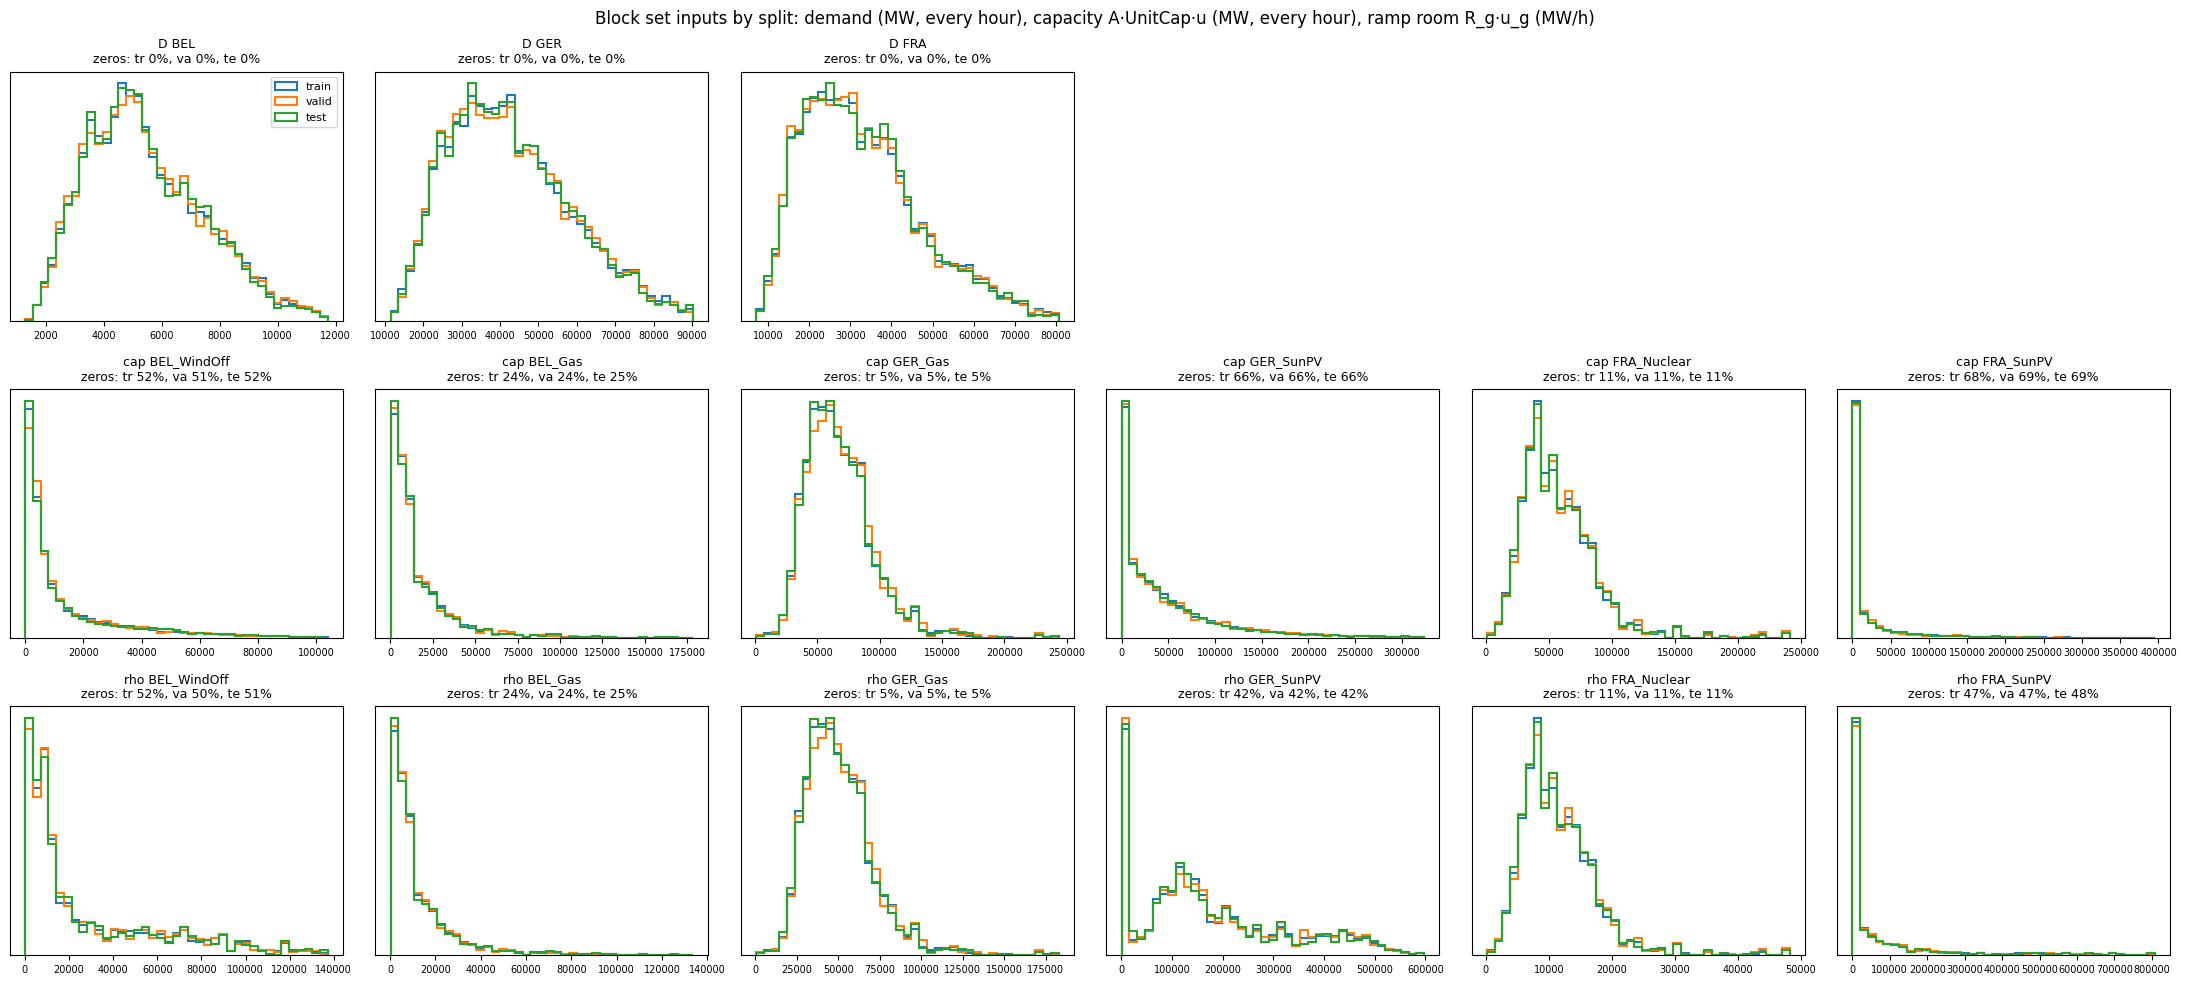

In [42]:
# Histograms per input, the three splits overlaid (density, so the split sizes do not matter).
# Capacity and ramp room have a spike at 0 (nothing built, or no sun/wind): its share is in the title,
# and the histogram shows the non-zero values only.
colors = {"train": "tab:blue", "valid": "tab:orange", "test": "tab:green"}
fig, axes = plt.subplots(3, 6, figsize=(22, 10))
panels = [[f"D {n}" for n in nodes], [f"cap {g}" for g in gens], [f"rho {g}" for g in gens]]
for row, names in zip(axes, panels):
    for ax in row[len(names):]:
        ax.axis("off")
    for ax, name in zip(row, names):
        v = feats[name]
        nz = v[v > 0]
        if nz.size == 0:
            ax.set_title(f"{name}\n(always 0)", fontsize=9)
            continue
        bins = np.linspace(nz.min(), np.quantile(nz, 0.995), 40)
        zero = []
        for s in SPLITS:
            x = v[split == s].ravel()
            zero.append(f"{s[:2]} {100 * (x == 0).mean():.0f}%")
            ax.hist(x[x > 0], bins=bins, density=True, histtype="step", lw=1.5, color=colors[s], label=s)
        ax.set_title(f"{name}\nzeros: " + ", ".join(zero), fontsize=9)
        ax.tick_params(labelsize=7)
        ax.set_yticks([])
axes[0, 0].legend(fontsize=8)
fig.suptitle("Block set inputs by split: demand (MW, every hour), capacity A·UnitCap·u (MW, every hour), ramp room R_g·u_g (MW/h)")
fig.tight_layout()
plt.show()


In [43]:
# What the split shares by construction. The split is random over (block, investment) pairs, and every
# block is paired with 30 investments (and every investment with 20 blocks). So a test row's demand
# window, and its investment, almost always appear in train too -- only their combination is new.
key_block = bi["inst"] * 10_000 + bi["block"]          # (instance, demand window)
key_inv = bi["inst"] * 10_000 + bi["inv"]              # (instance, investment)
train = split == "train"
comp = []
for s in SPLITS:
    m = split == s
    comp.append({
        "split": s, "blocks": int(m.sum()),
        "binding %": 100 * bi["binding"][m].mean(),
        "binding, impact > 5% (count)": int((bi["ramp_impact"][m] > 0.05).sum()),
        **{f"{c} %": 100 * (bi["class"][m] == c).mean() for c in np.unique(bi["class"])},
        "demand window also in train %": 100 * np.isin(key_block[m], key_block[train]).mean(),
        "investment also in train %": 100 * np.isin(key_inv[m], key_inv[train]).mean(),
        "Q* median": float(np.median(blk.opt_targets["obj"].numpy()[m])),
    })
pd.DataFrame(comp).set_index("split").round(2)


,blocks,binding %,"binding, impact > 5% (count)",high_demand %,middle %,renewable_heavy %,demand window also in train %,investment also in train %,Q* median
split,,,,,,,,,
train,38400,4.72,379,18.83,44.96,36.21,100.0,100.0,8335.40
valid,4800,4.81,47,18.90,45.17,35.94,100.0,100.0,8122.02
test,4800,4.48,41,17.96,45.19,36.85,100.0,100.0,8173.54


## Evlauation of Ramping

In [44]:
# Summary of the ramp evaluations: one row per (method, block group), as in the hourly comparison.
# Primal = cost of the dispatch after the ramp repair, against the exact block optimum Q*:
#   gap = (U - Q*) / Q*   (always >= 0: the repaired dispatch is feasible)
# Dual   = the lower bound L used for the Benders cut:  gap = (Q* - L) / Q*   (always >= 0)
# "total" = sum of the gaps over sum of Q* (large blocks weigh more; tiny-Q* blocks cannot dominate).
# The evaluation folder needs both ladder modes and the per-step arrays (eval_block_ladder.py after 2026-10-27):
#   venv/bin/python3 flowfirst/eval_block_ladder.py --run-dir flowfirst/runs/flowfirst-m0-blockhours-e250 \
#       --weights model_best.pt --out flowfirst/runs/ramp-ladder-eval/m0-blockhours-e250
EVAL_DIR = "flowfirst/runs/ramp-ladder-eval"
EVALS = {                                     # display name -> folder written by eval_block_ladder.py --out
    "method 0 (hourly net, block hours)": "m0-blockhours-e250",
    "hourly GNN (block hours)": "gnn-blockhours-e250",
    "2-ii space-time + paths (objective)": "paths-obj-e250",   # eval_block_ladder.py --run-dir .../flowfirst-spacetime-paths-trainBlock_obj-e250-2
    "2-ii space-time + paths (Lagrangian)": "paths-lagr-e250",
    # Way 2-iii (train_block.py --dp): its folders hold the no-LP pipeline ("dp") and, on the same flows, the LP ladder:
    #   venv/bin/python3 flowfirst/eval_block_ladder.py --run-dir flowfirst/runs/flowfirst-spacetime-dp-e100 \
    #       --weights model_best.pt --modes dp lp/infeasible lp/unmet --out flowfirst/runs/ramp-ladder-eval/dp-e100
    #   (the same with --polish-sweeps 1 --out flowfirst/runs/ramp-ladder-eval/dp-e100-polish)
    "2-iii space-time, dp loss (no LP)": "dp-e100",
    "2-iii space-time, dp loss (no LP) + polish": "dp-e100-polish",

    
    # "Plan A net (flowfirst-harvest)": "harvest",      # re-run its evaluation first (R1 fix)
}
MODE = "plan_A_lp_infeasible"                 # the ladder setting: R3 (exact block LP) only where R2 finds no dispatch
# a Way 2-iii folder is read in its own pipeline, "dp": R1, the node-block program (no LP), shrink, R4
mode_of = lambda z: "plan_A_dp" if "plan_A_dp_cost_gap" in z.files else MODE
RUNGS = {1: "no repair (dp: program at the net's flows)", 2: "R2 node LP", 3: "R3 exact LP", 4: "R4", 5: "shrink (no LP)"}


def groups(z):
    b, v, imp = z["binding"], z["violated"], z["impact"]
    return {"all": np.ones_like(b), "non-binding": ~b, "binding": b, "binding, impact > 5%": b & (imp > 0.05),
            "ramp broken by hourly net": v}


def gap_stats(gap, Q, m, prefix):
    g, q = gap[m], Q[m]
    return {f"{prefix}_gap_total (%)": 100 * (g * np.abs(q)).sum() / np.abs(q).sum(),
            f"{prefix}_within_1pct (%)": 100 * (g <= 0.01).mean(),
            f"{prefix}_gap_abs (mean)": (g * np.abs(q)).mean(),
            f"{prefix}_gap_mean (%)": 100 * g.mean(),
            f"{prefix}_gap_median (%)": 100 * np.median(g),
            f"{prefix}_gap_p99 (%)": 100 * np.quantile(g, 0.99)}


primal_rows, dual_rows, ladder_rows = [], [], []
for name, folder in EVALS.items():
    z = np.load(os.path.join(EVAL_DIR, folder, "blocks_test.npz"))
    Q, mode = z["Q"], mode_of(z)
    for grp, m in groups(z).items():
        key = {"experiment": name, "blocks": grp, "n": int(m.sum())}
        primal_rows.append({**key, "pipeline": mode[7:], **gap_stats(z[f"{mode}_cost_gap"], Q, m, "test_primal")})
        dual_rows.append({**key, "pipeline": mode[7:], **gap_stats(z[f"{mode}_bound_gap"], Q, m, "test_dual"),
                          "cut_slope_err_median (%)": 100 * np.median(z[f"{mode}_slope_err"][m])})
        rung = z[f"{mode}_rung"][m]
        ladder_rows.append({**key, **{f"{lbl} (%)": 100 * (rung == r).mean() for r, lbl in RUNGS.items()},
                            "no-repair cost gap_total (%)": gap_stats(z["level_A_cost_gap"], Q, m, "x")["x_gap_total (%)"]})

idx = ["experiment", "blocks", "n"]
primal = pd.DataFrame(primal_rows).set_index(idx)
dual = pd.DataFrame(dual_rows).set_index(idx)
ladder = pd.DataFrame(ladder_rows).set_index(idx)
print("==== Primal: cost after ramp repair vs exact block optimum ====")
display(primal.round(3))
print("==== Dual: lower bound (cut) vs exact block optimum ====")
display(dual.round(3))
print("==== Ramp repair: where each block ended; 'no-repair' = hourly answer ignoring ramps (can be infeasible, reference only) ====")
display(ladder.round(2))


==== Primal: cost after ramp repair vs exact block optimum ====


pipeline  test_primal_gap_total (%)  test_primal_within_1pct (%)  \
experiment                                 blocks                    n                                                                             
method 0 (hourly net, block hours)         all                       4800  lp_infeasible                      0.092                       84.667   
                                           non-binding               4585  lp_infeasible                      0.034                       86.499   
                                           binding                   215   lp_infeasible                     27.835                       45.581   
                                           binding, impact > 5%      41    lp_infeasible                    138.003                       48.780   
                                           ramp broken by hourly net 260   lp_infeasible                     18.217                       40.000   
hourly GNN (block hours)                   all                       4800  lp_infeasible                      0.072                       97.854   
                                           non-binding               4585  lp_infeasible                      0.002                       98.866   
                                           binding                   215   lp_infeasible                     33.116                       76.279   
                                           binding, impact > 5%      41    lp_infeasible                    165.906                       75.610   
                                           ramp broken by hourly net 224   lp_infeasible                     24.327                       74.107   
2-ii space-time + paths (objective)        all                       4800  lp_infeasible                      0.016                       79.667   
                                           non-binding               4585  lp_infeasible                      0.014                       81.745   
                                           binding                   215   lp_infeasible                      1.125                       35.349   
                                           binding, impact > 5%      41    lp_infeasible                     18.656                       21.951   
                                           ramp broken by hourly net 2173  lp_infeasible                      0.013                       91.671   
2-ii space-time + paths (Lagrangian)       all                       4800  lp_infeasible                      0.017                       78.562   
                                           non-binding               4585  lp_infeasible                      0.014                       81.200   
                                           binding                   215   lp_infeasible                      1.389                       22.326   
                                           binding, impact > 5%      41    lp_infeasible                      8.417                        2.439   
                                           ramp broken by hourly net 2121  lp_infeasible                      0.013                       91.231   
2-iii space-time, dp loss (no LP)          all                       4800             dp                      0.020                       75.062   
                                           non-binding               4585             dp                      0.018                       76.707   
                                           binding                   215              dp                      0.840                       40.000   
                                           binding, impact > 5%      41               dp                      4.942                       17.073   
                                           ramp broken by hourly net 665              dp                      0.004                       79.850   
2-iii space-time, dp loss (no LP) + polish all                       4800           

==== Dual: lower bound (cut) vs exact block optimum ====


pipeline  test_dual_gap_total (%)  test_dual_within_1pct (%)  \
experiment                                 blocks                    n                                                                         
method 0 (hourly net, block hours)         all                       4800  lp_infeasible                    0.008                     97.292   
                                           non-binding               4585  lp_infeasible                    0.007                     98.888   
                                           binding                   215   lp_infeasible                    0.316                     63.256   
                                           binding, impact > 5%      41    lp_infeasible                    2.492                     34.146   
                                           ramp broken by hourly net 260   lp_infeasible                    0.229                     70.769   
hourly GNN (block hours)                   all                       4800  lp_infeasible                    0.001                     98.333   
                                           non-binding               4585  lp_infeasible                    0.001                     99.847   
                                           binding                   215   lp_infeasible                    0.267                     66.047   
                                           binding, impact > 5%      41    lp_infeasible                    2.356                     41.463   
                                           ramp broken by hourly net 224   lp_infeasible                    0.193                     67.411   
2-ii space-time + paths (objective)        all                       4800  lp_infeasible                    0.001                     97.333   
                                           non-binding               4585  lp_infeasible                    0.000                     99.607   
                                           binding                   215   lp_infeasible                    0.607                     48.837   
                                           binding, impact > 5%      41    lp_infeasible                    7.532                      7.317   
                                           ramp broken by hourly net 2173  lp_infeasible                    0.000                     99.402   
2-ii space-time + paths (Lagrangian)       all                       4800  lp_infeasible                    0.002                     97.083   
                                           non-binding               4585  lp_infeasible                    0.001                     99.389   
                                           binding                   215   lp_infeasible                    0.620                     47.907   
                                           binding, impact > 5%      41    lp_infeasible                    7.831                      4.878   
                                           ramp broken by hourly net 2121  lp_infeasible                    0.001                     99.057   
2-iii space-time, dp loss (no LP)          all                       4800             dp                    0.001                     97.000   
                                           non-binding               4585             dp                    0.000                     99.280   
                                           binding                   215              dp                    0.629                     48.372   
                                           binding, impact > 5%      41               dp                    8.363                      0.000   
                                           ramp broken by hourly net 665              dp                    0.002                     86.165   
2-iii space-time, dp loss (no LP) + polish all                       4800             dp                    0.002                     97.229   
                                           non-b

==== Ramp repair: where each block ended; 'no-repair' = hourly answer ignoring ramps (can be infeasible, reference only) ====


no repair (dp: program at the net's flows) (%)  R2 node LP (%)  R3 exact LP (%)  \
experiment                                 blocks                    n                                                                                       
method 0 (hourly net, block hours)         all                       4800                                           94.58            5.42              0.0   
                                           non-binding               4585                                           98.69            1.31              0.0   
                                           binding                   215                                             6.98           93.02              0.0   
                                           binding, impact > 5%      41                                              0.00          100.00              0.0   
                                           ramp broken by hourly net 260                                             0.00          100.00              0.0   
hourly GNN (block hours)                   all                       4800                                           95.33            4.67              0.0   
                                           non-binding               4585                                           99.72            0.28              0.0   
                                           binding                   215                                             1.86           98.14              0.0   
                                           binding, impact > 5%      41                                              0.00          100.00              0.0   
                                           ramp broken by hourly net 224                                             0.00          100.00              0.0   
2-ii space-time + paths (objective)        all                       4800                                           54.73           45.27              0.0   
                                           non-binding               4585                                           53.44           46.56              0.0   
                                           binding                   215                                            82.33           17.67              0.0   
                                           binding, impact > 5%      41                                             90.24            9.76              0.0   
                                           ramp broken by hourly net 2173                                            0.00          100.00              0.0   
2-ii space-time + paths (Lagrangian)       all                       4800                                           55.81           44.19              0.0   
                                           non-binding               4585                                           54.53           45.47              0.0   
                                           binding                   215                                            83.26           16.74              0.0   
                                           binding, impact > 5%      41                                             92.68            7.32              0.0   
                                           ramp broken by hourly net 2121                                            0.00          100.00              0.0   
2-iii space-time, dp loss (no LP)          all                       4800                                          100.00            0.00              0.0   
                                           non-binding               4585                                          100.00            0.00              0.0   
                                           binding                   215                                           100.00            0.00              0.0   
                                           binding, impact > 5%      41                                            100.00    

In [ ]:
# Primal gap step by step: every block of the group goes through every step, so each column is the same blocks
# one step further down the pipeline, and the change between two columns is what that step adds.
#   1 network + clip      the hourly net's flows (R0 is inside the net), merit-order fill
#   2 + polish            one line-polish sweep: the hourly flow-first pipeline as it stands
#   3 + R1                flows that leave md outside [0, D] shrunk (changes feasibility, not cost)
#   4 + R2                broken node-blocks re-planned with the flows fixed; R3 only where R2 finds no dispatch
#   ref: + R3 on unmet    escalate="unmet": blocks where R2 adds unserved demand get the exact block LP instead
#   4' program, no LP     Way 2-iii folders only: R1, the node-block program on every node, shrink (no LP);
#                         compare with "4 + R2", the LP ladder on the same flows. "-" where a folder lacks a step.
# Steps 1-3 ignore the ramp limits, so their dispatch can be infeasible and even cheaper than Q* (negative gap).
# The last table says how many blocks are feasible after each step: generators within capacity, lines within
# limits, demand balanced, unserved demand between 0 and demand, and no generator ramping faster than its limit.
# Steps 4 and ref. are always feasible.
STEPS = {"1 network + clip": ("stage_clip_cost_gap", "stage_clip_feasible"),
         "2 + polish": ("stage_polish_cost_gap", "stage_polish_feasible"),
         "3 + R1": ("level_A_cost_gap", None),
         "4 + R2": ("plan_A_lp_infeasible_cost_gap", True),
         "ref: + R3 on unmet": ("plan_A_lp_unmet_cost_gap", True),
         "4' program, no LP": ("plan_A_dp_cost_gap", True)}

mean_rows, total_rows, feas_rows = [], [], []
for name, folder in EVALS.items():
    z = np.load(os.path.join(EVAL_DIR, folder, "blocks_test.npz"))
    Q = np.abs(z["Q"])
    for grp, m in groups(z).items():
        key = {"experiment": name, "blocks": grp, "n": int(m.sum())}
        mean_rows.append(dict(key))
        total_rows.append(dict(key))
        feas_rows.append(dict(key))
        for step, (gap_key, feas) in STEPS.items():
            if gap_key not in z.files:
                mean_rows[-1][step], total_rows[-1][step], feas_rows[-1][step] = "-", np.nan, np.nan
                continue
            g = z[gap_key][m]
            mean_rows[-1][step] = f"{100 * g.mean():.2f} ({100 * g.std():.2f})"
            total_rows[-1][step] = 100 * (g * Q[m]).sum() / Q[m].sum()
            ok = ~z["violated"] if feas is None else (np.ones(len(Q), bool) if feas is True else z[feas])   # after R1: the ramp check
            feas_rows[-1][step] = 100 * ok[m].mean()

print("==== Primal gap mean (std) in %, after each step ====")
display(pd.DataFrame(mean_rows).set_index(idx))
print("==== Primal gap total in % (sum of gaps over sum of Q*), after each step ====")
display(pd.DataFrame(total_rows).set_index(idx).round(3))
print("==== Feasible blocks (%) after each step: the dispatch breaks no constraint, ramp limits included ====")
display(pd.DataFrame(feas_rows).set_index(idx).round(1))


==== Primal gap mean (std) in %, after each step ====


1 network + clip        2 + polish         3 + R1            4 + R2  \
experiment                                 blocks                    n                                                                           
method 0 (hourly net, block hours)         all                       4800  282.75 (4948.88)      1.91 (17.48)   1.91 (17.48)    17.66 (284.70)   
                                           non-binding               4585  290.89 (5062.52)      2.02 (17.75)   2.02 (17.75)     4.68 (137.52)   
                                           binding                   215    109.18 (442.64)      -0.28 (9.63)   -0.28 (9.63)  294.36 (1151.59)   
                                           binding, impact > 5%      41     229.44 (448.22)     -7.46 (14.19)  -7.46 (14.19)  581.08 (2164.35)   
                                           ramp broken by hourly net 260   224.34 (1547.45)      1.51 (22.93)   1.51 (22.93)  292.18 (1188.11)   
hourly GNN (block hours)                   all                       4800      6.60 (84.03)      -0.11 (1.62)   -0.11 (1.62)    15.96 (307.14)   
                                           non-binding               4585      6.89 (85.95)       0.05 (0.60)    0.05 (0.60)       0.06 (0.68)   
                                           binding                   215        0.36 (9.50)      -3.62 (6.13)   -3.62 (6.13)  355.17 (1409.14)   
                                           binding, impact > 5%      41       -0.07 (20.67)     -13.57 (8.21)  -13.57 (8.21)  732.17 (2708.03)   
                                           ramp broken by hourly net 224        0.53 (9.56)      -3.48 (6.04)   -3.48 (6.04)  341.05 (1382.27)   
2-ii space-time + paths (objective)        all                       4800    20.51 (307.45)      5.16 (35.51)   5.16 (35.51)      3.54 (34.68)   
                                           non-binding               4585    20.69 (314.40)      4.93 (35.20)   4.93 (35.20)      3.27 (34.32)   
                                           binding                   215      16.60 (48.48)      9.91 (41.26)   9.91 (41.26)      9.26 (41.29)   
                                           binding, impact > 5%      41      52.24 (101.81)     34.68 (89.62)  34.68 (89.62)     33.80 (89.86)   
                                           ramp broken by hourly net 2173      4.68 (12.34)      3.94 (12.04)   3.94 (12.04)       0.38 (1.29)   
2-ii space-time + paths (Lagrangian)       all                       4800    21.81 (417.49)      3.64 (26.65)   3.63 (26.65)      3.13 (25.81)   
                                           non-binding               4585    22.28 (427.11)      3.36 (26.53)   3.36 (26.53)      2.84 (25.63)   
                                           binding                   215      11.88 (29.98)      9.59 (28.58)   9.59 (28.58)      9.33 (28.63)   
                                           binding, impact > 5%      41       36.58 (60.61)     32.41 (59.42)  32.41 (59.42)     32.11 (59.56)   
                                           ramp broken by hourly net 2121      1.78 (10.92)      1.52 (10.43)   1.51 (10.42)       0.37 (1.57)   
2-iii space-time, dp loss (no LP)          all                       4800  128.04 (2639.97)  128.04 (2639.97)   6.83 (53.65)      7.03 (54.02)   
                                           non-binding               4585  133.22 (2701.00)  133.22 (2701.00)   6.89 (54.68)      6.94 (54.86)   
                                           binding                   215      17.51 (71.79)     17.51 (71.79)   5.37 (22.08)      9.06 (31.11)   
                                           binding, impact > 5%      41      56.81 (149.45)    56.81 (149.45)  12.61 (45.71)     27.48 (65.41)   
                                           ramp broken by hourly net 665   877.61 (7045.09)  877.61 (7045.09)   2.71 (25.73)      4.21 (31.04)   
2-iii space-time, dp loss (no LP) + polish all                       4800  128.04 (2639.97)      0.43 (11.95)   0.43 (11.95)     9.29

==== Primal gap total in % (sum of gaps over sum of Q*), after each step ====


1 network + clip  2 + polish  3 + R1   4 + R2  ref: + R3 on unmet  \
experiment                                 blocks                    n                                                                         
method 0 (hourly net, block hours)         all                       4800             0.972       0.022   0.022    0.092               0.023   
                                           non-binding               4585             0.928       0.021   0.021    0.034               0.021   
                                           binding                   215             21.650       0.278   0.278   27.835               1.050   
                                           binding, impact > 5%      41             134.071      -6.002  -6.002  138.003               3.370   
                                           ramp broken by hourly net 260             22.616       0.298   0.298   18.217               0.607   
hourly GNN (block hours)                   all                       4800             0.038      -0.000  -0.000    0.072               0.002   
                                           non-binding               4585             0.039       0.002   0.002    0.002               0.002   
                                           binding                   215             -0.123      -0.748  -0.748   33.116               0.059   
                                           binding, impact > 5%      41              -4.272      -9.561  -9.561  165.906               0.199   
                                           ramp broken by hourly net 224              0.146      -0.543  -0.543   24.327               0.044   
2-ii space-time + paths (objective)        all                       4800             0.113       0.070   0.070    0.016               0.010   
                                           non-binding               4585             0.107       0.067   0.067    0.014               0.007   
                                           binding                   215              3.151       1.400   1.400    1.125               1.005   
                                           binding, impact > 5%      41              36.216      20.276  20.276   18.656              18.428   
                                           ramp broken by hourly net 2173             0.135       0.118   0.118    0.013               0.000   
2-ii space-time + paths (Lagrangian)       all                       4800             0.046       0.031   0.031    0.017               0.010   
                                           non-binding               4585             0.041       0.028   0.028    0.014               0.007   
                                           binding                   215              2.144       1.496   1.496    1.389               1.306   
                                           binding, impact > 5%      41              11.251       9.179   9.179    8.417               8.286   
                                           ramp broken by hourly net 2121             0.047       0.041   0.041    0.013               0.000   
2-iii space-time, dp loss (no LP)          all                       4800             0.108       0.108   0.018    0.020               0.020   
                                           non-binding               4585             0.101       0.101   0.018    0.018               0.018   
                                           binding                   215              3.157       3.157   0.109    0.840               0.840   
                                           binding, impact > 5%      41              31.170      31.170  -4.247    4.942               4.942   
                                           ramp broken by hourly net 665              0.139       0.139   0.001    0.004               0.003   
2-iii space-time, dp loss (no LP) + polish all                       4800             0.108      -0.000  -0.000    0.050               0.002   
                                           

==== Feasible blocks (%) after each step: the dispatch breaks no constraint, ramp limits included ====


1 network + clip  2 + polish  3 + R1  4 + R2  ref: + R3 on unmet  4' program, no LP
experiment                                 blocks                    n                                                                                        
method 0 (hourly net, block hours)         all                       4800              84.8        87.7    94.6   100.0               100.0                NaN
                                           non-binding               4585              88.0        91.5    98.7   100.0               100.0                NaN
                                           binding                   215               17.2         7.0     7.0   100.0               100.0                NaN
                                           binding, impact > 5%      41                 0.0         0.0     0.0   100.0               100.0                NaN
                                           ramp broken by hourly net 260               26.2         0.0     0.0   100.0               100.0                NaN
hourly GNN (block hours)                   all                       4800              87.2        88.5    95.3   100.0               100.0                NaN
                                           non-binding               4585              91.0        92.5    99.7   100.0               100.0                NaN
                                           binding                   215                7.4         1.9     1.9   100.0               100.0                NaN
                                           binding, impact > 5%      41                 0.0         0.0     0.0   100.0               100.0                NaN
                                           ramp broken by hourly net 224                9.8         0.0     0.0   100.0               100.0                NaN
2-ii space-time + paths (objective)        all                       4800              13.2        51.2    54.7   100.0               100.0                NaN
                                           non-binding               4585              12.3        49.7    53.4   100.0               100.0                NaN
                                           binding                   215               31.2        82.3    82.3   100.0               100.0                NaN
                                           binding, impact > 5%      41                34.1        90.2    90.2   100.0               100.0                NaN
                                           ramp broken by hourly net 2173               0.0         0.0     0.0   100.0               100.0                NaN
2-ii space-time + paths (Lagrangian)       all                       4800              13.2        52.2    55.8   100.0               100.0                NaN
                                           non-binding               4585              12.4        50.8    54.5   100.0               100.0                NaN
                                           binding                   215               31.6        83.3    83.3   100.0               100.0                NaN
                                           binding, impact > 5%      41                34.1        92.7    92.7   100.0               100.0                NaN
                                           ramp broken by hourly net 2121               0.0         0.0     0.0   100.0               100.0                NaN
2-iii space-time, dp loss (no LP)          all                       4800              86.1        86.1    86.1   100.0               100.0              100.0
                                           non-binding               4585              88.9        88.9    88.9   100.0               100.0              100.0
                                           binding                   215               27.4        27.4    27.4   100.0               100.0              100.0
                                           binding, impact > 5%      41                 9.8         

In [ ]:
import matplotlib as mpl
 
 
def _default_ylabel(metric):
    return {
        "dual_opt_gap (%)":    "Relative dual optimality gap (%)",
        "dual_opt_gap_abs":    "Absolute dual optimality gap",
        "dual_gap_median (%)": "Median relative dual gap (%)",
        "dual_gap_p90 (%)":    "P90 relative dual gap (%)",
        "dual_gap_p99 (%)":    "P99 relative dual gap (%)",
    }.get(metric, metric)
 
 
def _family_color(name):
    """Light heuristic so baseline-family and SLA-family read differently."""
    low = name.lower()
    if "soft" in low or "sla" in low or "beta" in low or "w=" in low:
        return "#6FB46B"          # SLA family  (green)
    if "superv" in low and "self" not in low:
        return "#E0975F"          # fully-supervised reference (amber)
    return "#9AA0A6"              # baseline family (gray)
 
 
def plot_dual_gap(
    stats_dict,
    split="test",
    metric="dual_opt_gap (%)",
    label_map=None,
    title=None,
    ylabel=None,
    colors=None,            # None -> family heuristic; or a single color str; or {name:color}
    show_points=True,       # overlay individual repeat runs
    n_label=True,           # annotate the number of runs per bar
    figsize=(9.5, 5.2),
    save_path=None,
    ax=None,
):
    """
    Bar plot of one dual-gap metric for every method in `stats_dict`,
    with individual repeat runs overlaid as points so outliers / spread
    are visible (bar = mean, error bar = +/-1 std across runs).
 
    stats_dict : output of evaluate_experiments_dual_only(...)
    metric     : "dual_opt_gap (%)" (default) | "dual_opt_gap_abs"
                 | "dual_gap_median (%)" | "dual_gap_p90 (%)" | "dual_gap_p99 (%)"
    Bars follow the insertion order of stats_dict.
    """
    mpl.rcParams.update({
        "font.family": "DejaVu Sans",
        "mathtext.fontset": "dejavusans",
        "axes.linewidth": 1.0,
        "axes.edgecolor": "#3a3a3a",
    })
 
    key = f"{split}_{metric}"
 
    names, labels, runs, means, stds = [], [], [], [], []
    for name, metrics in stats_dict.items():
        if key not in metrics:
            print(f"[plot_dual_gap] '{key}' missing for '{name}', skipping.")
            continue
        vals = np.asarray(metrics[key], dtype=float)
        vals = vals[~np.isnan(vals)]
        if vals.size == 0:
            print(f"[plot_dual_gap] no values for '{name}', skipping.")
            continue
        names.append(name)
        labels.append(label_map.get(name, name) if label_map else name)
        runs.append(vals)
        means.append(float(np.mean(vals)))
        stds.append(float(np.std(vals, ddof=1)) if vals.size > 1 else 0.0)
 
    if not names:
        sample = list(next(iter(stats_dict.values())).keys())[:6]
        raise ValueError(f"No method had metric key '{key}'. "
                         f"Example available keys: {sample}")
 
    # resolve colors
    if colors is None:
        bar_colors = [_family_color(n) for n in names]
    elif isinstance(colors, str):
        bar_colors = [colors] * len(names)
    else:
        bar_colors = [colors.get(n, _family_color(n)) for n in names]
 
    x = np.arange(len(names))
    created = ax is None
    if created:
        fig, ax = plt.subplots(figsize=figsize)
 
    # bars: mean with +/-1 std, muted fill so the points read on top
    ax.bar(x, means, yerr=stds, width=0.66, color=bar_colors, alpha=0.72,
           edgecolor="#2f2f2f", linewidth=0.9, zorder=2,
           error_kw=dict(ecolor="#2f2f2f", elinewidth=1.3, capsize=5,
                         capthick=1.3, zorder=4))
 
    # individual repeat runs as jittered points
    if show_points:
        rng = np.random.default_rng(0)
        for xi, v in zip(x, runs):
            if v.size <= 1:
                jitter = np.zeros_like(v)
            else:
                jitter = (rng.random(v.size) - 0.5) * 0.26
            ax.scatter(xi + jitter, v, s=26, color="#1f1f1f",
                       edgecolor="white", linewidth=0.6, zorder=5)
 
    # value labels: mean (std), placed above each bar's whisker
    top = max(np.max(v) for v in runs)
    for xi, m, s, v in zip(x, means, stds, runs):
        ytxt = max(m + s, np.max(v)) + top * 0.045
        ax.text(xi, ytxt, f"{m:.1f} ({s:.1f})", ha="center", va="bottom",
                fontsize=10, fontweight="bold", color="#222222")
 
    # n annotation: single value if uniform; else label each bar under its tick
    if n_label:
        ns = [len(v) for v in runs]
        if len(set(ns)) == 1:
            ax.text(0.99, 0.97, f"n = {ns[0]} runs", transform=ax.transAxes,
                    ha="right", va="top", fontsize=10, color="#666666")
        else:
            for xi, k in zip(x, ns):
                ax.text(xi, -top * 0.085, f"n={k}", ha="center", va="top",
                        fontsize=8.5, color="#888888")
 
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=0, fontsize=11)
    ax.set_ylabel(ylabel or _default_ylabel(metric), fontsize=12)
    ax.set_title(title or "Dual optimality gap",
                 fontsize=13.5, fontweight="bold", pad=12)
    ax.set_ylim(0, top * 1.26)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", labelsize=10.5)
    ax.yaxis.grid(True, color="#e6e6e6", linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
 
    if created:
        fig.tight_layout()
        if save_path:
            fig.savefig(save_path, dpi=200, bbox_inches="tight", facecolor="white")
        return fig, ax
    return ax
 
 
def plot_dual_gap_box(
    stats_dict,
    split="test",
    metric="dual_opt_gap (%)",
    label_map=None,
    title=None,
    ylabel=None,
    colors=None,
    show_points=True,
    figsize=(9.5, 5.2),
    save_path=None,
    ax=None,
):
    mpl.rcParams.update({
        "font.family": "serif", "mathtext.fontset": "cm",
        "axes.linewidth": 0.9, "axes.edgecolor": "#3a3a3a",
    })

    key = f"{split}_{metric}"
    names, labels, runs = [], [], []
    for name, metrics in stats_dict.items():
        if key not in metrics: continue
        vals = np.asarray(metrics[key], dtype=float)
        vals = vals[~np.isnan(vals)]
        if vals.size == 0: continue
        names.append(name)
        labels.append(label_map.get(name, name) if label_map else name)
        runs.append(vals)

    if not names:
        raise ValueError(f"No method had metric key '{key}'.")

    if colors is None:
        box_colors = [_family_color(n) for n in names]
    elif isinstance(colors, str):
        box_colors = [colors] * len(names)
    else:
        box_colors = [colors.get(n, _family_color(n)) for n in names]

    x = np.arange(len(names))
    created = ax is None
    if created:
        fig, ax = plt.subplots(figsize=figsize)

    bp = ax.boxplot(runs, positions=x, widths=0.55, patch_artist=True,
                    medianprops=dict(color="#1a1a1a", linewidth=1.6),
                    whiskerprops=dict(color="#3a3a3a", linewidth=1.0),
                    capprops=dict(color="#3a3a3a", linewidth=1.0),
                    flierprops=dict(marker="o", markersize=4,
                                    markerfacecolor="white",
                                    markeredgecolor="#3a3a3a", alpha=0.9))
    for patch, c in zip(bp["boxes"], box_colors):
        patch.set_facecolor(c); patch.set_alpha(0.7)
        patch.set_edgecolor("#2f2f2f"); patch.set_linewidth(0.9)

    if show_points:
        rng = np.random.default_rng(0)
        for xi, v in zip(x, runs):
            jitter = (rng.random(v.size) - 0.5) * 0.18 if v.size > 1 else np.zeros_like(v)
            ax.scatter(xi + jitter, v, s=22, color="#1f1f1f",
                       edgecolor="white", linewidth=0.5, zorder=5)

    top = max(np.max(v) for v in runs)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=11)
    ax.set_ylabel(ylabel or _default_ylabel(metric), fontsize=12)
    if title:
        ax.set_title(title, fontsize=13, pad=10)
    ax.set_ylim(0, top * 1.10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.yaxis.grid(True, color="#e6e6e6", linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

    if created:
        fig.tight_layout()
        if save_path:
            fig.savefig(save_path, bbox_inches="tight", facecolor="white")
        return fig, ax
    return ax

def plot_experiments_dual_gap(
    data,
    experiment_folder,
    experiments,
    repeats=3,
    split="test",
    metric="dual_opt_gap (%)",
    label_map=None,
    title=None,
    save_path=None,
    verbose=False,
    **plot_kwargs,
):
    """Evaluate then plot, same call style as evaluate_experiments_dual_only.
    Extra keyword args (show_points, colors, figsize, ...) pass through to plot_dual_gap."""
    stats_dict = evaluate_experiments_dual_only(
        data=data, experiment_folder=experiment_folder, experiments=experiments,
        repeats=repeats, splits=(split,), verbose=verbose,
    )
    # fig, ax = plot_dual_gap(stats_dict, split=split, metric=metric,
    #                         label_map=label_map, title=title,
    #                         save_path=save_path, **plot_kwargs)
    fig, ax = plot_dual_gap_box(
        stats_dict,
        label_map=label_map,
        title = title,
        save_path="fig_dual_gap_box.pdf",
        figsize=(11, 5.3),
    )
    return stats_dict, fig, ax
 

## Deep Dive analysis of the 2ii space time Lagrangian model

In [46]:
# In this block just load the model and the test data for me
from flowfirst.dataset import load_or_create
from flowfirst.spacetime import load_spacetime

LAGR_RUN = "flowfirst/runs/flowfirst-spacetime-paths-trainBlock_lagr-e250"
BLOCKS = "data/ED_data_gen/GEP_block_data_N3_G6_L3_H876_B4_single.pkl"

ds = pickle.load(open(BLOCKS, "rb"))                                   # the block set (all splits)
data, _ = load_or_create(json.load(open(os.path.join(LAGR_RUN, "args.json")))["config"])
net = load_spacetime(LAGR_RUN, data, ds, weights="model_best.pt")     # 2-ii Lagrangian, eval mode

bi = ds.block_info
test = bi["split"] == "test"
X_test = ds.X[torch.as_tensor(test)]                                   # block rows [K, B*N + B*G + G]
K, N, G = int(test.sum()), ds.num_n, ds.num_g
D_test = X_test[:, :B * N].numpy().reshape(K, B, N)                    # demand per hour
apmax_test, u_test = bi["apmax"][test], bi["u"][test]                  # A*UnitCap per hour, investment
Q_test = ds.opt_targets["obj"].numpy()[test]                           # exact block optimum Q*
bind_test, impact_test = bi["binding"][test], bi["ramp_impact"][test]

print(f"model: {LAGR_RUN} (model_best.pt), ramp-limited: {[ds.G[g] for g in net.slow.tolist()]}")
print(f"test blocks: {K}, binding: {int(bind_test.sum())}, impact > 5%: {int((bind_test & (impact_test > 0.05)).sum())}")


model: flowfirst/runs/flowfirst-spacetime-paths-trainBlock_lagr-e250 (model_best.pt), ramp-limited: [('BEL', 'Gas'), ('GER', 'Gas'), ('FRA', 'Nuclear')]
test blocks: 4800, binding: 215, impact > 5%: 41


## I want to see the mean median 90% 99% of primal gap

In [7]:
def block_groups(z):
    """Block groups of one blocks_<split>.npz, by name."""
    b, imp = z["binding"], z["impact"]
    return {"all": np.ones(len(b), bool),
            "non-binding": ~b,
            "binding": b,
            "binding, impact > 5%": b & (imp > 0.05),
            "ramp broken by hourly net": z["violated"]}


def evaluate_block_experiments(experiment_folder, experiments, baseline=None, split="test",
                               groups=("all", "binding", "binding, impact > 5%"), pipeline=None, tol=1e-6):
    """Primal gap (U - Q*)/Q* of eval_block_ladder.py folders, one row per (group, experiment).

    experiments: display name -> folder in experiment_folder (written by eval_block_ladder.py --out).
    baseline:    a name in experiments; adds per-block counts of blocks better / worse than it
                 (paired: same blocks, same order, checked).
    pipeline:    key prefix such as "plan_A_dp" or "plan_A_lp_infeasible"; default "plan_A_dp" where the
                 folder has it (Way 2-iii), else "plan_A_lp_infeasible".
    """
    loaded = {name: np.load(os.path.join(experiment_folder, folder, f"blocks_{split}.npz"))
              for name, folder in experiments.items()}
    ref = loaded[baseline] if baseline is not None else next(iter(loaded.values()))
    for name, z in loaded.items():
        assert np.array_equal(z["idx"], ref["idx"]), f"{name}: different blocks than the reference"
    Q = np.abs(ref["Q"])
    masks = block_groups(ref)

    def gap_of(z):
        p = pipeline or ("plan_A_dp" if "plan_A_dp_cost_gap" in z.files else "plan_A_lp_infeasible")
        return z[f"{p}_cost_gap"], p[len("plan_A_"):]

    g_base = gap_of(ref)[0] if baseline is not None else None
    rows = []
    for grp in groups:
        m = masks[grp]
        for name, z in loaded.items():
            gap, pipe = gap_of(z)
            g, q = gap[m], Q[m]
            row = {"group": grp, "experiment": name, "pipeline": pipe, "blocks": int(m.sum()),
                   "gap total (%)": 100 * (g * q).sum() / q.sum(),
                   "gap mean (%)": 100 * g.mean(),
                   "gap median (%)": 100 * np.median(g),
                   "gap p90 (%)": 100 * np.quantile(g, 0.90),
                   "gap p99 (%)": 100 * np.quantile(g, 0.99),
                   "within 1% (%)": 100 * (g <= 0.01).mean()}
            if baseline is not None and name != baseline:
                d = g - g_base[m]
                row[f"better than {baseline}"] = int((d < -tol).sum())
                row[f"worse than {baseline}"] = int((d > tol).sum())
            rows.append(row)
    df = pd.DataFrame(rows).set_index(["group", "experiment"])
    counts = [c for c in df.columns if c.startswith(("better than", "worse than"))]
    return df.astype({c: "Int64" for c in counts})


def pretty_display_blocks(df, digits=3):
    """One table per block group."""
    for grp, sub in df.groupby(level="group", sort=False):
        print(f"=== {grp} ({int(sub['blocks'].iloc[0])} blocks) ===")
        sub = sub.droplevel("group").drop(columns="blocks").round(digits)
        display(sub.astype(object).where(sub.notna(), "-"))


In [9]:
experiment_folder = "flowfirst/runs/ramp-ladder-eval"
experiments = {
    "128 wide, 3 rounds": "dp-e100",
    "64 wide, 3 rounds": "dp-h64r3",
    "64 wide, 4 rounds": "dp-h64r4",
}

stats_df = evaluate_block_experiments(
    experiment_folder=experiment_folder,
    experiments=experiments,
    baseline="128 wide, 3 rounds",
    # groups=("all", "binding", "binding, impact > 5%", "non-binding", "ramp broken by hourly net"),
)
pretty_display_blocks(stats_df)


=== all (4800 blocks) ===


,pipeline,gap total (%),gap mean (%),gap median (%),gap p90 (%),gap p99 (%),within 1% (%),"better than 128 wide, 3 rounds","worse than 128 wide, 3 rounds"
experiment,,,,,,,,,
"128 wide, 3 rounds",dp,0.02,7.035,0.092,5.374,177.607,75.062,-,-
"64 wide, 3 rounds",dp,0.029,10.769,0.124,9.225,317.778,72.208,1315,2336
"64 wide, 4 rounds",dp,0.024,7.922,0.144,8.102,209.177,66.417,892,3168


=== binding (215 blocks) ===


,pipeline,gap total (%),gap mean (%),gap median (%),gap p90 (%),gap p99 (%),within 1% (%),"better than 128 wide, 3 rounds","worse than 128 wide, 3 rounds"
experiment,,,,,,,,,
"128 wide, 3 rounds",dp,0.84,9.065,1.656,17.61,105.971,40.0,-,-
"64 wide, 3 rounds",dp,0.976,10.187,2.179,18.656,126.363,35.349,63,146
"64 wide, 4 rounds",dp,0.769,7.589,2.093,13.691,74.086,33.488,87,125


=== binding, impact > 5% (41 blocks) ===


,pipeline,gap total (%),gap mean (%),gap median (%),gap p90 (%),gap p99 (%),within 1% (%),"better than 128 wide, 3 rounds","worse than 128 wide, 3 rounds"
experiment,,,,,,,,,
"128 wide, 3 rounds",dp,4.942,27.481,3.949,57.671,288.115,17.073,-,-
"64 wide, 3 rounds",dp,5.555,29.839,5.793,65.625,290.782,14.634,14,27
"64 wide, 4 rounds",dp,4.405,21.136,4.188,51.04,208.817,12.195,22,19
